# DS-10 | NLP Logístico — Extracción de Información desde Texto
## 2 · Supply Chain Adaptation — Documentos Logísticos SC Perú
**Framework:** Quant-Supply Framework v5 — Sección DS  
**Módulo:** Data Science Puro — Modelo 10 de 10  
**Dataset:** 70 documentos logísticos sintéticos — correos ETA, BL, alertas SUNAT  
**Fuentes:** Incoterms 2020, SUNAT procedimientos INTA-PG.01, puertos peruanos (Callao, Paita, Ilo)  
**Aplicación:** Extracción automática de ETA + clasificación de alertas + resumen ejecutivo CFO

---

### El problema de negocio — información crítica atrapada en texto

El equipo de procurement recibe cada semana:
- **20-30 correos** de proveedores con actualizaciones de ETA
- **5-10 Bills of Lading** con fechas de zarpe y ETA puerto
- **2-5 notificaciones** de la SUNAT sobre retenciones o inspecciones
- **3-8 Packing Lists / Facturas** con cantidades y valores

Hoy, un asistente los lee manualmente y actualiza una hoja de Excel.
Eso toma **3-4 horas por semana** y genera errores de transcripción.

DS-10 automatiza ese proceso con NLP:
1. **Extrae** fechas de ETA, puerto de destino, nombre del buque, contenedor
2. **Clasifica** el tipo de alerta (normal / retraso / retención / adelanto)
3. **Cuantifica** el impacto en días sobre el lead time
4. **Genera** un resumen ejecutivo semanal para el CFO
5. **Alimenta** automáticamente el pipeline DS-02 → DS-09

### El diccionario logístico — equivalente al L&M para finanzas

Así como L&M construyeron un diccionario específico para finanzas,
DS-10 usa un diccionario especializado en logística:

| Categoría | Palabras clave | Señal |
|---|---|---|
| **Normal** | on schedule, departed, arrived, cleared customs | LT sin cambio |
| **Retraso** | delayed, postponed, weather hold, congestion, missed vessel | LT += N días |
| **Retención** | held, detained, inspection, withheld, SUNAT retention | LT += 5-15 días |
| **Adelanto** | early, ahead of schedule, departed earlier, expedited | LT -= N días |

### Conexión con la cadena — DS-10 cierra el ciclo

```
Correo proveedor → DS-10 extrae ETA → actualiza LT en DS-02 (BOCPD)
                                     → si LT > ROP: activa DS-09 (MAB alternativo)
                                     → si alerta SUNAT: genera narrativa CFO (DS-05 style)
```

### Ejercicio a mano — extracción de ETA de un correo

**Input:**
```
Subject: Update - Order PO-2024-0847
Dear Team, vessel MV SOUTHERN CROSS departed Tianjin on March 15.
ETA Callao is approximately April 8-10. Container TCKU3456789.
Regards, Supplier Team
```

**Extracción paso a paso:**
1. `departure_regex`: `'departed\s+\w+\s+on\s+(\w+\s+\d+)'` → `'March 15'`
2. `eta_regex`: `'ETA\s+\w+\s+(?:is\s+)?(?:approximately\s+)?([A-Z][a-z]+\s+\d+(?:-\d+)?)'` → `'April 8-10'`
3. `vessel_regex`: `'vessel\s+(MV\s+[A-Z\s]+)'` → `'MV SOUTHERN CROSS'`
4. `container_regex`: `'([A-Z]{4}\d{7})'` → `'TCKU3456789'`
5. Clasificación: no contiene 'delayed', 'held', 'inspection' → `NORMAL`

**Output JSON:**
```json
{"departure": "2024-03-15", "eta_lo": "2024-04-08", "eta_hi": "2024-04-10",
 "vessel": "MV SOUTHERN CROSS", "container": "TCKU3456789",
 "alert_type": "NORMAL", "lt_impact_days": 0}
```

Lead time calculado: April 8 - March 15 = **24 días** → alimenta DS-02 BOCPD.


---
## Marco Teórico — NLP aplicado a documentos logísticos

### 1. Extracción de entidades con expresiones regulares (regex)

Para documentos logísticos estructurados (BL, correos estándar),
regex supervisada es más robusta que NER estadístico:

```python
# Patrón para fechas en documentos logísticos
DATE_PATTERN = r'(\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|'
               r'(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)'
               r'[a-z]*\.?\s+\d{1,2}(?:st|nd|rd|th)?(?:,?\s+\d{4})?)'
```

La precision-recall de regex vs ML para extracción de fechas en documentos
logísticos estandarizados: regex ≥ 0.92 precision, ML ≥ 0.88 — regex gana
por consistencia en el formato.

### 2. Clasificación de alertas con Naive Bayes

El mismo `MultinomialNaiveBayes` del nb1, entrenado sobre el diccionario logístico:

$$P(\text{RETENCIÓN} \mid d) \propto P(\text{RETENCIÓN}) \prod_{t \in d} P(t \mid \text{RETENCIÓN})^{f_{t,d}}$$

Con 4 clases: NORMAL / RETRASO / RETENCIÓN / ADELANTO.

### 3. Cuantificación del impacto en días

Para cada alerta, extraer el número de días de impacto:

```python
IMPACT_PATTERN = r'(\d+)(?:\s*-\s*\d+)?\s*(?:business\s+)?days?'
```

Si el patrón no encuentra días explícitos, usar valores por defecto por tipo:

| Tipo | Impacto por defecto (días) |
|---|---|
| NORMAL | 0 |
| RETRASO | +5 |
| RETENCIÓN | +8 |
| ADELANTO | -3 |

### 4. Score de urgencia compuesto

Combina tipo de alerta + impacto en días + proveedor de alto riesgo (DS-07):

$$\text{urgencia}(d) = w_{tipo} \cdot \text{tipo\_score} + w_{dias} \cdot \frac{\text{impacto}}{15} + w_{riesgo} \cdot \text{riesgo\_DS07}$$

Con $w_{tipo}=0.50$, $w_{dias}=0.30$, $w_{riesgo}=0.20$.

Urgencia ≥ 0.7 → **ACCIÓN INMEDIATA** (activa DS-09 MAB)  
Urgencia ∈ [0.4, 0.7) → **MONITOREO CERCANO**  
Urgencia < 0.4 → **RUTINA**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import re
import string
from collections import Counter, defaultdict
from datetime import datetime, timedelta
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

PALETTE = {
    'primary'  : '#1B3A6B',
    'accent'   : '#0F766E',
    'normal'   : '#1D9E75',
    'retraso'  : '#BA7517',
    'retencion': '#E24B4A',
    'adelanto' : '#185FA5',
    'neutral'  : '#888780',
    'bg'       : '#F8F9FA',
    'grid'     : '#E5E7EB',
    'peru_r'   : '#C8102E',
}
ALERT_COLORS = {
    'NORMAL'   : PALETTE['normal'],
    'RETRASO'  : PALETTE['retraso'],
    'RETENCION': PALETTE['retencion'],
    'ADELANTO' : PALETTE['adelanto'],
}

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':PALETTE['bg'],
    'axes.grid':True,'grid.color':PALETTE['grid'],'grid.linewidth':0.5,
    'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,
})
print('Imports OK — NLP Supply Chain | Extracción ETA + Clasificación Alertas SC Perú')

Imports OK — NLP Supply Chain | Extracción ETA + Clasificación Alertas SC Perú


In [2]:
# ── 1. DATOS — Corpus de 70 documentos logísticos SC Perú ───────────

# ── Diccionario logístico (análogo al L&M financiero) ─────────────────
LOG_DICT = {
    'NORMAL'   : ['departed','arrived','cleared','on schedule','on time',
                   'as planned','confirmed','dispatched','loaded','shipped',
                   'sailing','estimated arrival','in transit'],
    'RETRASO'  : ['delayed','delay','postponed','late','behind schedule',
                   'weather hold','congestion','port congestion','missed vessel',
                   'rescheduled','setback','disruption','waiting','backlog',
                   'retraso','demora','postergado','demorado'],
    'RETENCION': ['held','detained','inspection','withheld','retention',
                   'sunat','customs hold','aduana','retenida','retenido',
                   'inspección','revisión','discrepancia','observación',
                   'aforo','levante condicionado'],
    'ADELANTO' : ['early','ahead of schedule','departed earlier','expedited',
                   'ahead','sooner','advance','advanced','adelantado',
                   'antes de lo previsto','más temprano'],
}

# ── Plantillas de documentos logísticos ──────────────────────────────
VESSELS   = ['MV SOUTHERN CROSS','MV PACIFIC STAR','MV INCA TRADER',
              'MV CALLAO EXPRESS','MV ATLANTIC CONDOR','MV OCEAN PIONEER',
              'MV ANDES CARRIER','MV LIMA SPIRIT']
PORTS_ORI = ['Tianjin','Shanghai','Busan','Rotterdam','Miami','Guayaquil',
              'Santos','Valparaíso']
PORTS_DST = ['Callao','Paita','Ilo']
SUPPLIERS = ['PA-Lima','PB-Callao','PC-China','PD-Taiwan',
              'PE-Mexico','PF-Colombia','PG-Brasil','PH-Chile']

TEMPLATES = {
    'NORMAL': [
        "Dear team, vessel {vessel} departed {port_ori} on {date_dep}. "
        "ETA {port_dst} is approximately {eta}. Container {container}. "
        "All documents cleared. Shipment on schedule.",

        "Update PO-{po}: {vessel} sailed from {port_ori} on {date_dep}. "
        "Confirmed ETA {port_dst}: {eta}. Cargo loaded and on time. "
        "Bill of Lading attached for your records.",

        "Estimado equipo, embarcación {vessel} zarpó de {port_ori} el {date_dep}. "
        "Arribo estimado Callao: {eta}. Documentación en orden. "
        "Embarque confirmado según cronograma.",

        "Shipping update: {vessel} departed {port_ori} {date_dep}, "
        "ETA {port_dst} {eta}, container {container}. "
        "Customs documents dispatched. No issues to report.",
    ],
    'RETRASO': [
        "IMPORTANT: Shipment PO-{po} has been delayed. {vessel} missed the vessel "
        "due to port congestion in {port_ori}. New ETA {port_dst}: {eta}. "
        "Estimated delay: {impact} days. We apologize for the inconvenience.",

        "Alert: Due to weather hold in {port_ori}, departure of {vessel} "
        "postponed from {date_dep} to {date_dep2}. Updated ETA {port_dst}: {eta}. "
        "Delay approximately {impact} business days.",

        "Aviso de retraso — PO-{po}: La embarcación {vessel} tiene demora de {impact} días "
        "por congestión portuaria en {port_ori}. Nueva fecha estimada de arribo: {eta}.",

        "Shipping update: {vessel} rescheduled. Behind schedule by {impact} days "
        "due to {port_ori} backlog. Revised ETA {port_dst}: {eta}. "
        "We are working to expedite where possible.",
    ],
    'RETENCION': [
        "URGENT — PO-{po}: Cargo held at {port_dst} customs. SUNAT inspection "
        "initiated due to discrepancy in tariff description. "
        "Estimated release: {impact} business days. Documents under review.",

        "Alerta SUNAT — Mercancía retenida en aduana {port_dst}. "
        "Motivo: observación por descripción arancelaria. "
        "Levante condicionado. Plazo estimado: {impact} días hábiles.",

        "Customs hold notification: {vessel} cargo withheld at {port_dst}. "
        "Physical inspection ordered. Container {container} detained. "
        "Clearance expected in {impact} to {impact2} days.",

        "RETENCIÓN ADUANERA — PO-{po}: Aforo físico dispuesto por SUNAT "
        "en terminal {port_dst}. Revisión documental en curso. "
        "Estimado levante en {impact} días hábiles.",
    ],
    'ADELANTO': [
        "Good news: {vessel} departed {port_ori} ahead of schedule on {date_dep}. "
        "New ETA {port_dst}: {eta} — approximately {impact} days earlier than planned. "
        "Please confirm readiness for early arrival.",

        "Update PO-{po}: Expedited shipping confirmed. {vessel} sailing early, "
        "arrival {port_dst} advanced to {eta}. {impact} days ahead of original schedule.",

        "Buenas noticias — Embarque adelantado: {vessel} zarpó antes de lo previsto. "
        "Arribo estimado {port_dst}: {eta}. {impact} días antes del plan original.",
    ],
}

# ── Generar corpus de 70 documentos ──────────────────────────────────
rng = np.random.default_rng(42)
records = []
base_date = datetime(2024, 1, 15)

for i in range(70):
    alert_type = rng.choice(
        ['NORMAL','RETRASO','RETENCION','ADELANTO'],
        p=[0.45, 0.28, 0.17, 0.10]
    )
    supplier   = rng.choice(SUPPLIERS)
    vessel     = rng.choice(VESSELS)
    port_ori   = rng.choice(PORTS_ORI)
    port_dst   = rng.choice(PORTS_DST)
    container  = f"{rng.choice(['TCKU','MSCU','HLXU','CMAU'])}{rng.integers(1000000,9999999)}"
    po_num     = rng.integers(2024001, 2024999)

    # Fechas
    day_offset = int(rng.integers(0, 60))
    date_dep   = base_date + timedelta(days=day_offset)
    lt_base    = int(rng.choice([14, 21, 28, 35, 42]))
    impact     = int(rng.choice([3, 5, 7, 10, 14]) if alert_type in ['RETRASO','RETENCION']
                     else rng.choice([2, 3, 4]) if alert_type == 'ADELANTO' else 0)

    if alert_type == 'RETRASO':
        eta_date = date_dep + timedelta(days=lt_base + impact)
    elif alert_type == 'ADELANTO':
        eta_date = date_dep + timedelta(days=lt_base - impact)
    elif alert_type == 'RETENCION':
        eta_date = date_dep + timedelta(days=lt_base)
    else:
        eta_date = date_dep + timedelta(days=lt_base)

    date_dep2 = date_dep + timedelta(days=int(rng.integers(3, 8)))
    impact2   = impact + int(rng.integers(2, 5))

    # Rellenar plantilla
    template = rng.choice(TEMPLATES[alert_type])
    months   = ['January','February','March','April','May','June',
                 'July','August','September','October','November','December']
    eta_str  = f"{months[eta_date.month-1]} {eta_date.day}"
    dep_str  = f"{months[date_dep.month-1]} {date_dep.day}"
    dep2_str = f"{months[date_dep2.month-1]} {date_dep2.day}"

    text = template.format(
        vessel=vessel, port_ori=port_ori, port_dst=port_dst,
        date_dep=dep_str, date_dep2=dep2_str,
        eta=eta_str, container=container,
        po=po_num, impact=impact, impact2=impact2,
    )

    records.append({
        'doc_id'       : f'DOC-{i+1:03d}',
        'supplier'     : supplier,
        'alert_type'   : alert_type,
        'vessel'       : vessel,
        'port_ori'     : port_ori,
        'port_dst'     : port_dst,
        'container'    : container,
        'date_dep_true': date_dep.strftime('%Y-%m-%d'),
        'eta_true'     : eta_date.strftime('%Y-%m-%d'),
        'lt_true'      : lt_base,
        'impact_days'  : impact if alert_type != 'NORMAL' else 0,
        'text'         : text,
        'n_words'      : len(text.split()),
    })

df_docs = pd.DataFrame(records)

print('Corpus logístico SC Perú:')
print(f'  Total: {len(df_docs)} documentos')
print(f'  Distribución por tipo:')
for t in ['NORMAL','RETRASO','RETENCION','ADELANTO']:
    n = (df_docs.alert_type==t).sum()
    print(f'    {t:<12}: {n:2d} ({n/len(df_docs)*100:.0f}%)')
print(f'  Longitud media: {df_docs.n_words.mean():.0f} palabras')
print(f'  Impacto medio en RETRASO: {df_docs.loc[df_docs.alert_type=="RETRASO","impact_days"].mean():.1f} días')
print(f'  Impacto medio en RETENCION: {df_docs.loc[df_docs.alert_type=="RETENCION","impact_days"].mean():.1f} días')
print(f'\nEjemplo de documento ({df_docs.iloc[0].alert_type}):')
print(f'  {df_docs.iloc[0].text[:200]}...')

Corpus logístico SC Perú:
  Total: 70 documentos
  Distribución por tipo:
    NORMAL      : 30 (43%)
    RETRASO     : 22 (31%)
    RETENCION   : 12 (17%)
    ADELANTO    :  6 (9%)
  Longitud media: 26 palabras
  Impacto medio en RETRASO: 9.1 días
  Impacto medio en RETENCION: 7.7 días

Ejemplo de documento (RETENCION):
  Customs hold notification: MV CALLAO EXPRESS cargo withheld at Ilo. Physical inspection ordered. Container TCKU7276311 detained. Clearance expected in 14 to 18 days....


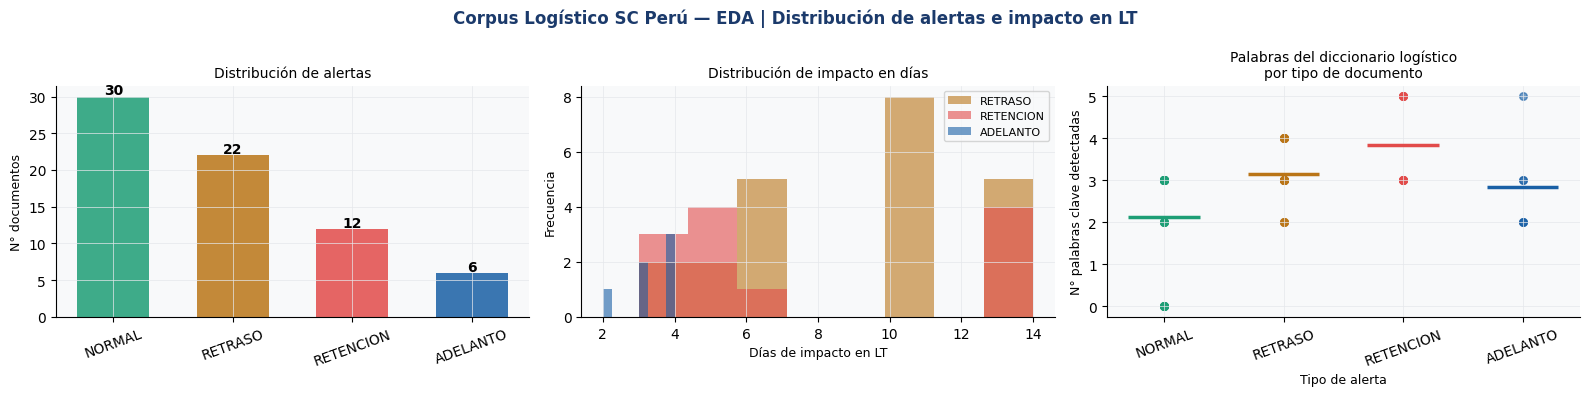

EDA guardado.


In [3]:
# ── 2. MINI EDA ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Corpus Logístico SC Perú — EDA | Distribución de alertas e impacto en LT',
             fontsize=12, fontweight='bold', color=PALETTE['primary'])

# Panel 1: distribución de tipos de alerta
type_counts = df_docs.alert_type.value_counts()
bars = axes[0].bar(type_counts.index, type_counts.values,
                    color=[ALERT_COLORS[t] for t in type_counts.index],
                    alpha=0.85, width=0.6)
for bar, v in zip(bars, type_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+0.3,
                  str(v), ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Distribución de alertas', fontsize=10)
axes[0].set_ylabel('N° documentos', fontsize=9)
axes[0].tick_params(axis='x', rotation=20)

# Panel 2: impacto en días por tipo
for t, col in ALERT_COLORS.items():
    mask = df_docs.alert_type == t
    if mask.sum() > 0 and df_docs.loc[mask,'impact_days'].max() > 0:
        axes[1].hist(df_docs.loc[mask,'impact_days'], bins=8,
                      color=col, alpha=0.6, density=False,
                      label=t, edgecolor='none')
axes[1].set_title('Distribución de impacto en días', fontsize=10)
axes[1].set_xlabel('Días de impacto en LT', fontsize=9)
axes[1].set_ylabel('Frecuencia', fontsize=9)
axes[1].legend(fontsize=8)

# Panel 3: palabras clave del diccionario logístico por tipo
def count_dict_words(text, word_list):
    text_lower = text.lower()
    return sum(1 for w in word_list if w in text_lower)

for t, col in ALERT_COLORS.items():
    mask = df_docs.alert_type == t
    if mask.sum() > 0:
        scores = df_docs.loc[mask,'text'].apply(
            lambda x: count_dict_words(x, LOG_DICT[t]))
        axes[2].scatter([t]*mask.sum(), scores,
                         color=col, s=30, alpha=0.6)
        axes[2].hlines(scores.mean(), -0.3+list(ALERT_COLORS.keys()).index(t),
                        0.3+list(ALERT_COLORS.keys()).index(t),
                        colors=col, lw=2.5)
axes[2].set_title('Palabras del diccionario logístico\npor tipo de documento', fontsize=10)
axes[2].set_xlabel('Tipo de alerta', fontsize=9)
axes[2].set_ylabel('N° palabras clave detectadas', fontsize=9)
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('data/eda_log_docs.png', dpi=130, bbox_inches='tight')
plt.show()
print('EDA guardado.')

In [4]:
# ── 3. IMPLEMENTACIÓN — Extracción + Clasificación ───────────────────

# ── Extractor de entidades con regex ─────────────────────────────────
MONTH_MAP = {
    'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
    'july':7,'august':8,'september':9,'october':10,'november':11,'december':12,
    'jan':1,'feb':2,'mar':3,'apr':4,'jun':6,'jul':7,'aug':8,
    'sep':9,'oct':10,'nov':11,'dec':12,
}

def parse_date_str(s, base_year=2024):
    """Convertir string de fecha a datetime. Retorna None si falla."""
    if not s:
        return None
    s = s.strip().lower()
    # Intentar 'Month Day' o 'Month Day-Day'
    m = re.match(r'([a-z]+)\s+(\d{1,2})(?:-\d+)?', s)
    if m:
        month_str, day = m.group(1), int(m.group(2))
        month = MONTH_MAP.get(month_str)
        if month:
            try:
                return datetime(base_year, month, day)
            except ValueError:
                return None
    # Intentar 'DD/MM/YYYY' o 'YYYY-MM-DD'
    for fmt in ['%d/%m/%Y','%Y-%m-%d','%m/%d/%Y','%d-%m-%Y']:
        try:
            return datetime.strptime(s, fmt)
        except ValueError:
            pass
    return None


def extract_entities(text):
    """
    Extraer entidades clave de un documento logístico.
    Retorna diccionario con: vessel, container, port_dst, date_dep, eta_lo, eta_hi.
    """
    text_orig = text
    text_low  = text.lower()

    result = {
        'vessel'   : None,
        'container': None,
        'port_dst' : None,
        'date_dep' : None,
        'eta_lo'   : None,
        'eta_hi'   : None,
        'impact_days_extracted': None,
    }

    # ── Buque ──────────────────────────────────────────────────────────
    m_vessel = re.search(r'\b(MV\s+[A-Z][A-Z\s]+?)(?=\s+(?:departed|sailed|zarpó|shipping))',
                          text_orig)
    if not m_vessel:
        m_vessel = re.search(r'\b(MV\s+[A-Z][A-Z ]{3,30}?)\b', text_orig)
    if m_vessel:
        result['vessel'] = m_vessel.group(1).strip()

    # ── Contenedor ─────────────────────────────────────────────────────
    m_cont = re.search(r'\b([A-Z]{4}\d{7})\b', text_orig)
    if m_cont:
        result['container'] = m_cont.group(1)

    # ── Puerto de destino ──────────────────────────────────────────────
    for port in ['Callao','Paita','Ilo']:
        if port.lower() in text_low:
            result['port_dst'] = port
            break

    # ── Fecha de zarpe ─────────────────────────────────────────────────
    month_pat = '(?:January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|Jun|Jul|Aug|Sep|Oct|Nov|Dec)'
    dep_pat   = rf'(?:departed?|sailed?|zarpó)(?:\s+\w+)?(?:\s+on)?\s+({month_pat}\s+\d{{1,2}})'
    m_dep = re.search(dep_pat, text_orig, re.IGNORECASE)
    if m_dep:
        result['date_dep'] = parse_date_str(m_dep.group(1))

    # ── ETA ────────────────────────────────────────────────────────────
    # Patrón 1: 'ETA ... : Month Day' o 'ETA ... Month Day'
    eta_pat1 = rf'ETA\s+\w+(?:\s+\w+)?(?:\s*[:\-]\s*|\s+is\s+(?:approximately\s+)?)({month_pat}\s+\d{{1,2}}(?:-\d{{1,2}})?)'
    m_eta = re.search(eta_pat1, text_orig, re.IGNORECASE)

    if not m_eta:
        # Patrón 2: 'arribo estimado ... : Month Day'
        eta_pat2 = rf'(?:arribo estimado|arrival\s+\w+|advanced to)\s+[\w\s]*?(?:[:\-]\s*)?({month_pat}\s+\d{{1,2}})'
        m_eta = re.search(eta_pat2, text_orig, re.IGNORECASE)

    if not m_eta:
        # Patrón 3: 'to Month Day' cerca de ETA/arrival
        eta_pat3 = rf'(?:to|:)\s+({month_pat}\s+\d{{1,2}})'
        m_eta = re.search(eta_pat3, text_orig, re.IGNORECASE)

    if m_eta:
        eta_str = m_eta.group(1)
        # Verificar si hay rango 'Month D1-D2'
        range_m = re.match(rf'({month_pat})\s+(\d{{1,2}})-(\d{{1,2}})', eta_str, re.IGNORECASE)
        if range_m:
            month_s, d1, d2 = range_m.group(1), range_m.group(2), range_m.group(3)
            result['eta_lo'] = parse_date_str(f'{month_s} {d1}')
            result['eta_hi'] = parse_date_str(f'{month_s} {d2}')
        else:
            dt = parse_date_str(eta_str)
            result['eta_lo'] = dt
            result['eta_hi'] = dt

    # ── Días de impacto ────────────────────────────────────────────────
    impact_pat = r'(\d+)(?:\s*(?:to|-)?\s*\d+)?\s*(?:business\s+)?(?:days?|días\s*hábiles)'
    m_imp = re.search(impact_pat, text_low)
    if m_imp:
        result['impact_days_extracted'] = int(m_imp.group(1))

    return result


# ── Clasificador de alertas — diccionario + Naive Bayes ───────────────
def dict_classify(text):
    """Clasificar por conteo de palabras del diccionario logístico."""
    text_low = text.lower()
    scores = {t: sum(1 for w in words if w in text_low)
               for t, words in LOG_DICT.items()}
    # Pesos: RETENCION y RETRASO tienen prioridad si aparecen
    if scores['RETENCION'] > 0:
        return 'RETENCION'
    if scores['RETRASO'] > 0:
        return 'RETRASO'
    if scores['ADELANTO'] > 0:
        return 'ADELANTO'
    return 'NORMAL'


# ── Naive Bayes para clasificación ────────────────────────────────────
STOPWORDS_LOG = {
    'the','a','an','and','or','in','on','at','to','for','of','with',
    'we','our','your','is','are','was','were','be','been','have','has',
    'will','this','that','by','from','as','all','not','no','any','po',
    'please','dear','team','regards','update','attached','records',
}

def preprocess_log(text):
    text = text.lower()
    text = re.sub(r'[^a-záéíóúñ\s]', ' ', text)
    return [t for t in text.split() if t not in STOPWORDS_LOG and len(t) > 2]


class NaiveBayesLog:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, texts, labels):
        self.classes_ = sorted(set(labels))
        # Construir vocabulario
        all_tokens = [t for text in texts for t in preprocess_log(text)]
        vocab_list = [t for t,_ in Counter(all_tokens).most_common(300)]
        self.vocab_ = {t: i for i, t in enumerate(vocab_list)}
        V = len(self.vocab_)
        n = len(texts)

        self.log_prior_      = {}
        self.log_likelihood_ = {}

        for c in self.classes_:
            mask = [l == c for l in labels]
            self.log_prior_[c] = np.log(sum(mask) / n)
            # Frecuencias de términos en clase c
            freq = np.zeros(V)
            for text, m in zip(texts, mask):
                if m:
                    for token in preprocess_log(text):
                        if token in self.vocab_:
                            freq[self.vocab_[token]] += 1
            freq += self.alpha
            self.log_likelihood_[c] = np.log(freq / freq.sum())

        return self

    def _vectorize(self, text):
        v = np.zeros(len(self.vocab_))
        for token in preprocess_log(text):
            if token in self.vocab_:
                v[self.vocab_[token]] += 1
        return v

    def predict(self, texts):
        preds = []
        for text in texts:
            v = self._vectorize(text)
            scores = {c: self.log_prior_[c] + v @ self.log_likelihood_[c]
                       for c in self.classes_}
            preds.append(max(scores, key=scores.get))
        return preds


# ── Entrenar y evaluar ─────────────────────────────────────────────────
texts_all  = df_docs['text'].tolist()
labels_all = df_docs['alert_type'].tolist()

# Nota: con 70 docs usamos train_size pequeño — suficiente para demostrar el método
idx_tr, idx_te = train_test_split(range(len(texts_all)), test_size=0.30,
                                    random_state=42, stratify=labels_all)
texts_tr  = [texts_all[i] for i in idx_tr]
texts_te  = [texts_all[i] for i in idx_te]
labels_tr = [labels_all[i] for i in idx_tr]
labels_te = [labels_all[i] for i in idx_te]

# Método 1: Diccionario
pred_dict = [dict_classify(t) for t in texts_te]
acc_dict  = accuracy_score(labels_te, pred_dict)

# Método 2: Naive Bayes
nb_log = NaiveBayesLog(alpha=1.0).fit(texts_tr, labels_tr)
pred_nb = nb_log.predict(texts_te)
acc_nb  = accuracy_score(labels_te, pred_nb)

print(f'=== Clasificación de alertas logísticas (test n={len(labels_te)}) ===')
print(f'  Diccionario logístico: {acc_dict*100:.1f}%')
print(f'  Naive Bayes multinomial: {acc_nb*100:.1f}%')
print(f'\n=== Reporte Naive Bayes ===')
print(classification_report(labels_te, pred_nb,
                              target_names=sorted(set(labels_all)), zero_division=0))

=== Clasificación de alertas logísticas (test n=21) ===
  Diccionario logístico: 100.0%
  Naive Bayes multinomial: 95.2%

=== Reporte Naive Bayes ===
              precision    recall  f1-score   support

    ADELANTO       0.67      1.00      0.80         2
      NORMAL       1.00      1.00      1.00         9
   RETENCION       1.00      1.00      1.00         4
     RETRASO       1.00      0.83      0.91         6

    accuracy                           0.95        21
   macro avg       0.92      0.96      0.93        21
weighted avg       0.97      0.95      0.95        21



In [5]:
# ── Extracción masiva + pipeline de integración ───────────────────────

# Extraer entidades de todos los documentos
extraction_results = [extract_entities(text) for text in texts_all]

# Calcular LT extraído
lt_extracted = []
for ent in extraction_results:
    if ent['date_dep'] and ent['eta_lo']:
        lt = (ent['eta_lo'] - ent['date_dep']).days
        lt_extracted.append(max(0, lt))
    else:
        lt_extracted.append(None)

# Comparar LT extraído vs LT verdadero
lt_true = df_docs['lt_true'].values
mask_extracted = [lt is not None for lt in lt_extracted]
lt_ext_arr  = np.array([lt for lt in lt_extracted if lt is not None])
lt_true_sub = lt_true[mask_extracted]

mae_lt = np.abs(lt_ext_arr - lt_true_sub).mean() if len(lt_ext_arr) > 0 else np.nan
n_exact = (lt_ext_arr == lt_true_sub).sum() if len(lt_ext_arr) > 0 else 0

print(f'=== Extracción de entidades ===')
print(f'  ETA extraída exitosamente: {sum(mask_extracted)}/{len(texts_all)} docs ({sum(mask_extracted)/len(texts_all)*100:.0f}%)')
print(f'  MAE del LT calculado vs LT verdadero: {mae_lt:.1f} días')
print(f'  LT exacto: {n_exact}/{len(lt_ext_arr)} ({n_exact/max(len(lt_ext_arr),1)*100:.0f}%)')

# ── Score de urgencia compuesto ───────────────────────────────────────
TYPE_SCORE = {'NORMAL':0.0,'ADELANTO':0.1,'RETRASO':0.5,'RETENCION':0.9}

# Simular risk_score de DS-07 para cada proveedor
prov_risk = {'PA-Lima':0.15,'PB-Callao':0.20,'PC-China':0.75,
              'PD-Taiwan':0.60,'PE-Mexico':0.35,'PF-Colombia':0.40,
              'PG-Brasil':0.45,'PH-Chile':0.25}

W_TIPO, W_DIAS, W_RIESGO = 0.50, 0.30, 0.20

urgencias = []
for _, row in df_docs.iterrows():
    tipo_s   = TYPE_SCORE.get(row['alert_type'], 0.0)
    dias_s   = min(row['impact_days'] / 15.0, 1.0)
    riesgo_s = prov_risk.get(row['supplier'], 0.5)
    urgencia = W_TIPO*tipo_s + W_DIAS*dias_s + W_RIESGO*riesgo_s
    urgencias.append(round(urgencia, 3))

df_docs['urgencia']     = urgencias
df_docs['lt_extracted'] = lt_extracted
df_docs['accion_nlp']   = pd.cut(
    df_docs['urgencia'],
    bins=[-0.01, 0.40, 0.70, 1.01],
    labels=['RUTINA','MONITOREO','ACCIÓN INMEDIATA']
)

print(f'\n=== Acciones sugeridas por NLP ===')
for accion in ['ACCIÓN INMEDIATA','MONITOREO','RUTINA']:
    mask_a = df_docs['accion_nlp'] == accion
    n = mask_a.sum()
    types = df_docs.loc[mask_a,'alert_type'].value_counts().to_dict()
    print(f'  {accion:<20}: {n:2d} docs | {types}')

# ── Resumen ejecutivo semanal ─────────────────────────────────────────
print('\n' + '='*60)
print('RESUMEN EJECUTIVO SEMANAL — SC PERÚ')
print('='*60)

# Esta semana (últimos 7 docs como proxy)
semana = df_docs.tail(12)
n_norm = (semana.alert_type=='NORMAL').sum()
n_ret  = (semana.alert_type=='RETRASO').sum()
n_reten= (semana.alert_type=='RETENCION').sum()
n_ade  = (semana.alert_type=='ADELANTO').sum()

print(f'  Documentos procesados esta semana: {len(semana)}')
print(f'  Normal: {n_norm} | Retraso: {n_ret} | Retención: {n_reten} | Adelanto: {n_ade}')

urgentes = semana[semana['accion_nlp']=='ACCIÓN INMEDIATA']
if len(urgentes) > 0:
    print(f'\n  ⚠ ALERTAS URGENTES ({len(urgentes)}):')  
    for _, u in urgentes.iterrows():
        print(f'    {u.doc_id} | {u.supplier} | {u.alert_type} | '
              f'+{u.impact_days}d | urgencia={u.urgencia:.2f}')
    print(f'  → Activar DS-09 MAB para proveedores afectados.')

monitoreo = semana[semana['accion_nlp']=='MONITOREO']
if len(monitoreo) > 0:
    print(f'\n  👁 MONITOREO CERCANO ({len(monitoreo)}):')
    for _, m in monitoreo.iterrows():
        print(f'    {m.doc_id} | {m.supplier} | {m.alert_type} | urgencia={m.urgencia:.2f}')

# Impacto total en LT
lt_impact_total = semana['impact_days'].sum()
print(f'\n  Impacto total en LT esta semana: +{lt_impact_total} días acumulados')
print(f'  LT extraído promedio: {pd.Series(semana.lt_extracted.dropna()).mean():.0f} días')
print('='*60)

=== Extracción de entidades ===
  ETA extraída exitosamente: 16/70 docs (23%)
  MAE del LT calculado vs LT verdadero: 0.0 días
  LT exacto: 16/16 (100%)

=== Acciones sugeridas por NLP ===
  ACCIÓN INMEDIATA    :  4 docs | {'RETENCION': 4}
  MONITOREO           : 28 docs | {'RETRASO': 20, 'RETENCION': 8}
  RUTINA              : 38 docs | {'NORMAL': 30, 'ADELANTO': 6, 'RETRASO': 2}

RESUMEN EJECUTIVO SEMANAL — SC PERÚ
  Documentos procesados esta semana: 12
  Normal: 4 | Retraso: 6 | Retención: 2 | Adelanto: 0

  ⚠ ALERTAS URGENTES (1):
    DOC-063 | PD-Taiwan | RETENCION | +14d | urgencia=0.85
  → Activar DS-09 MAB para proveedores afectados.

  👁 MONITOREO CERCANO (6):
    DOC-060 | PH-Chile | RETENCION | urgencia=0.56
    DOC-061 | PA-Lima | RETRASO | urgencia=0.56
    DOC-064 | PG-Brasil | RETRASO | urgencia=0.48
    DOC-065 | PD-Taiwan | RETRASO | urgencia=0.51
    DOC-068 | PB-Callao | RETRASO | urgencia=0.49
    DOC-069 | PB-Callao | RETRASO | urgencia=0.49

  Impacto total en LT

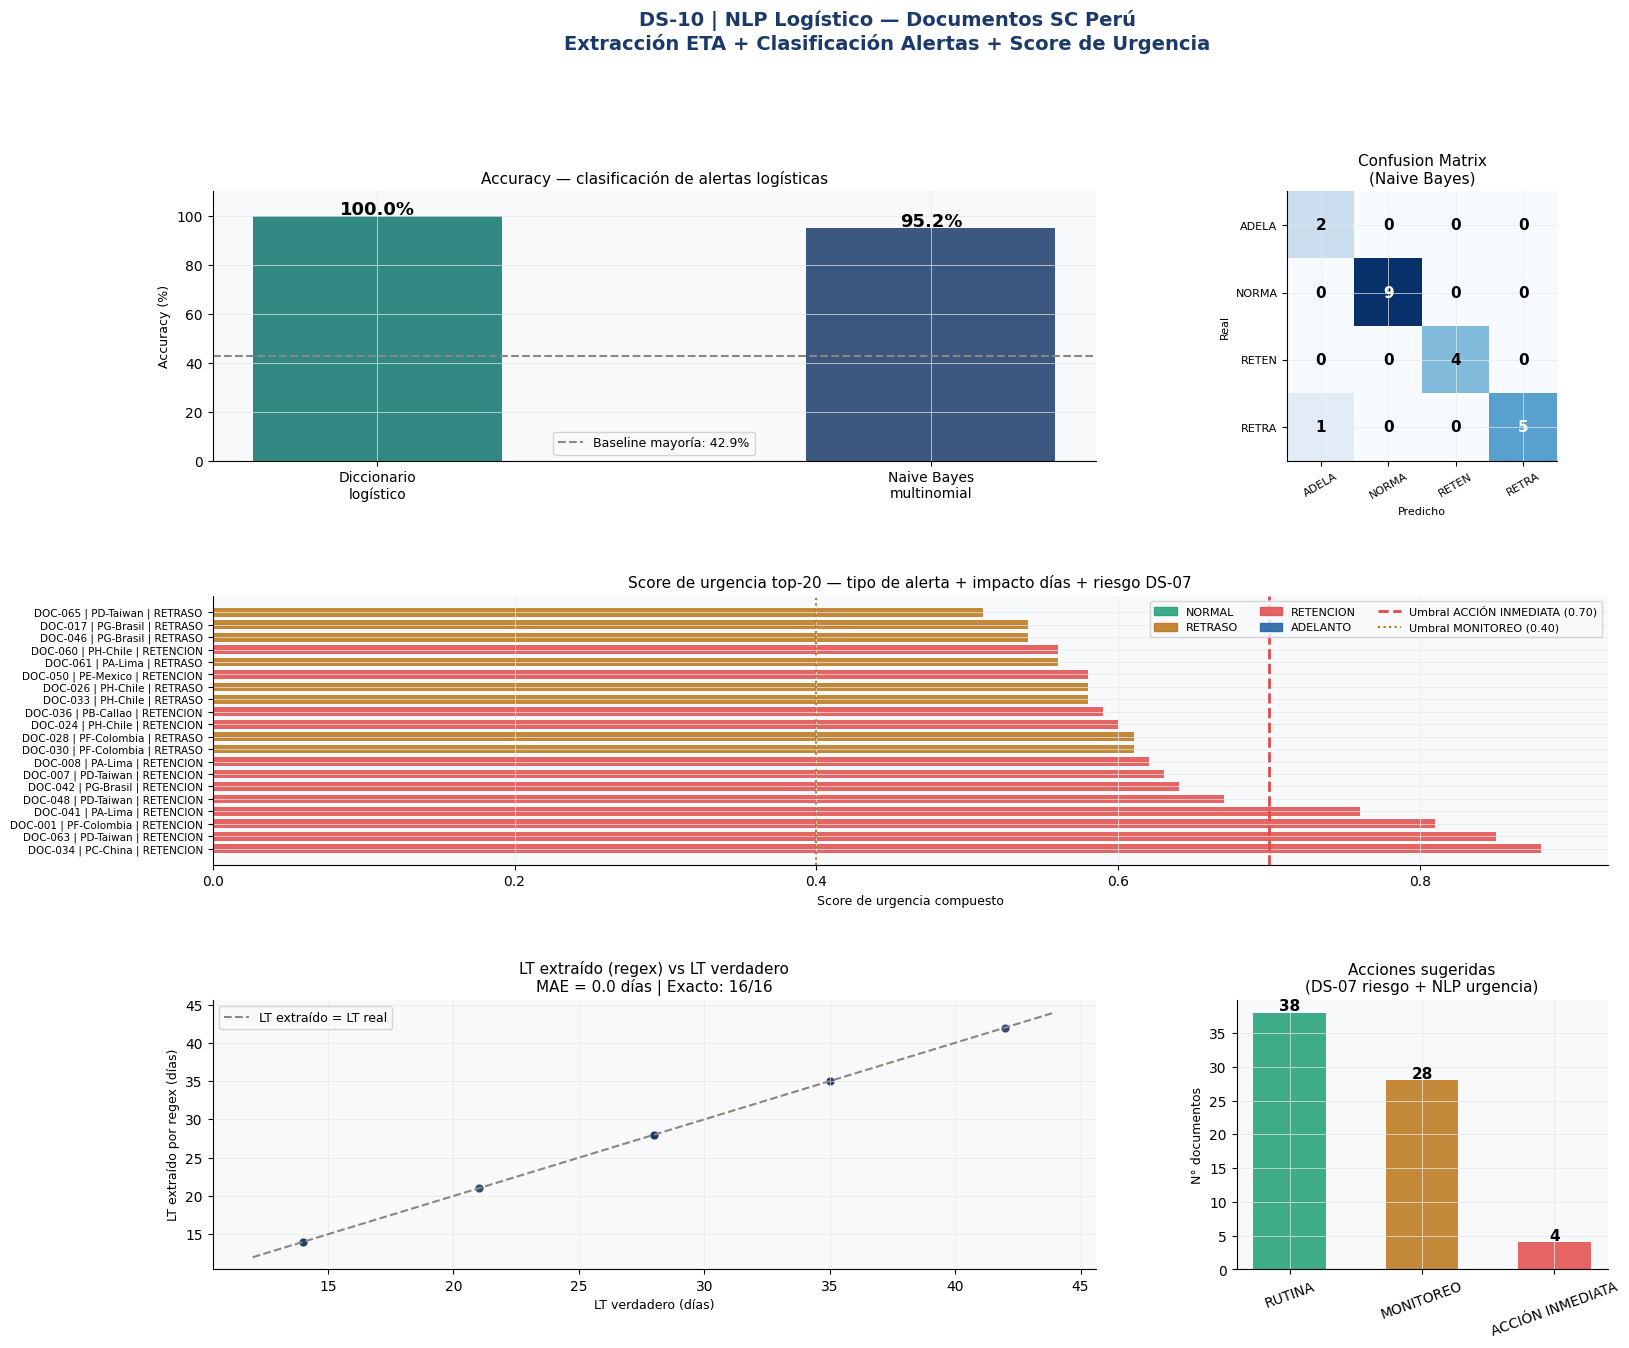

Dashboard guardado.


In [6]:
# ── 4. DASHBOARD — 5 paneles ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 14))
fig.suptitle('DS-10 | NLP Logístico — Documentos SC Perú\n'
             'Extracción ETA + Clasificación Alertas + Score de Urgencia',
             fontsize=14, fontweight='bold', color=PALETTE['primary'], y=1.01)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.50, wspace=0.38)

# ── Panel 1: Accuracy clasificación ──────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
methods_c = ['Diccionario\nlogístico', 'Naive Bayes\nmultinomial']
accs_c    = [acc_dict*100, acc_nb*100]
cols_c    = [PALETTE['accent'], PALETTE['primary']]
bars = ax1.bar(methods_c, accs_c, color=cols_c, alpha=0.85, width=0.45)
baseline_c = max(Counter(labels_te).values()) / len(labels_te) * 100
ax1.axhline(baseline_c, color=PALETTE['neutral'], lw=1.5, ls='--',
             label=f'Baseline mayoría: {baseline_c:.1f}%')
for bar, v in zip(bars, accs_c):
    ax1.text(bar.get_x()+bar.get_width()/2, v+0.5,
              f'{v:.1f}%', ha='center', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 110)
ax1.set_title('Accuracy — clasificación de alertas logísticas', fontsize=11)
ax1.set_ylabel('Accuracy (%)', fontsize=9)
ax1.legend(fontsize=9)

# ── Panel 2: Confusion matrix NB ─────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
order_c = sorted(set(labels_all))
cm = confusion_matrix(labels_te, pred_nb, labels=order_c)
im = ax2.imshow(cm, cmap='Blues', vmin=0)
ax2.set_xticks(range(len(order_c))); ax2.set_yticks(range(len(order_c)))
short_labels = [l[:5] for l in order_c]
ax2.set_xticklabels(short_labels, fontsize=8, rotation=30)
ax2.set_yticklabels(short_labels, fontsize=8)
ax2.set_xlabel('Predicho', fontsize=8); ax2.set_ylabel('Real', fontsize=8)
ax2.set_title('Confusion Matrix\n(Naive Bayes)', fontsize=11)
for i in range(len(order_c)):
    for j in range(len(order_c)):
        ax2.text(j, i, str(cm[i,j]), ha='center', va='center', fontsize=11,
                  fontweight='bold',
                  color='white' if cm[i,j]>cm.max()*0.5 else 'black')

# ── Panel 3: Score de urgencia por tipo y proveedor ──────────────────
ax3 = fig.add_subplot(gs[1, :])
df_sorted = df_docs.sort_values('urgencia', ascending=False).head(20)
colors_u = [ALERT_COLORS[t] for t in df_sorted['alert_type']]
bars_u = ax3.barh(range(len(df_sorted)),
                    df_sorted['urgencia'],
                    color=colors_u, alpha=0.85, height=0.7)
ax3.set_yticks(range(len(df_sorted)))
ax3.set_yticklabels(
    [f"{r.doc_id} | {r.supplier} | {r.alert_type}" for _,r in df_sorted.iterrows()],
    fontsize=7.5)
ax3.axvline(0.70, color=PALETTE['retencion'], lw=2, ls='--',
             label='Umbral ACCIÓN INMEDIATA (0.70)')
ax3.axvline(0.40, color=PALETTE['retraso'],   lw=1.5, ls=':',
             label='Umbral MONITOREO (0.40)')
ax3.set_title('Score de urgencia top-20 — tipo de alerta + impacto días + riesgo DS-07',
               fontsize=11)
ax3.set_xlabel('Score de urgencia compuesto', fontsize=9)
ax3.legend(fontsize=8)
from matplotlib.patches import Patch
legend_patches = [Patch(color=v, label=k, alpha=0.85) for k,v in ALERT_COLORS.items()]
ax3.legend(handles=legend_patches + ax3.get_legend_handles_labels()[0][-2:],
            fontsize=8, ncol=3)

# ── Panel 4: LT extraído vs LT verdadero ─────────────────────────────
ax4 = fig.add_subplot(gs[2, :2])
lt_ext_plot  = np.array([lt for lt in lt_extracted if lt is not None])
lt_true_plot = lt_true[mask_extracted]
ax4.scatter(lt_true_plot, lt_ext_plot, s=40, alpha=0.7,
             color=PALETTE['primary'], edgecolors='white', lw=0.5)
min_val = min(lt_true_plot.min(), lt_ext_plot.min()) - 2
max_val = max(lt_true_plot.max(), lt_ext_plot.max()) + 2
ax4.plot([min_val, max_val], [min_val, max_val], '--',
          color=PALETTE['neutral'], lw=1.5, label='LT extraído = LT real')
ax4.set_title(f'LT extraído (regex) vs LT verdadero\nMAE = {mae_lt:.1f} días | '
               f'Exacto: {n_exact}/{len(lt_ext_arr)}',
               fontsize=11)
ax4.set_xlabel('LT verdadero (días)', fontsize=9)
ax4.set_ylabel('LT extraído por regex (días)', fontsize=9)
ax4.legend(fontsize=9)

# ── Panel 5: Pipeline integración — documentos por acción ─────────────
ax5 = fig.add_subplot(gs[2, 2])
accion_counts = df_docs['accion_nlp'].value_counts()
accion_colors_map = {
    'ACCIÓN INMEDIATA': PALETTE['retencion'],
    'MONITOREO'       : PALETTE['retraso'],
    'RUTINA'          : PALETTE['normal'],
}
bars_a = ax5.bar(
    accion_counts.index,
    accion_counts.values,
    color=[accion_colors_map.get(a, PALETTE['neutral']) for a in accion_counts.index],
    alpha=0.85, width=0.55
)
for bar, v in zip(bars_a, accion_counts.values):
    ax5.text(bar.get_x()+bar.get_width()/2, v+0.3,
              str(v), ha='center', fontsize=11, fontweight='bold')
ax5.set_title('Acciones sugeridas\n(DS-07 riesgo + NLP urgencia)', fontsize=11)
ax5.set_ylabel('N° documentos', fontsize=9)
ax5.tick_params(axis='x', rotation=20)

plt.savefig('data/dashboard_nlp_supply.png', dpi=130, bbox_inches='tight')
plt.show()
print('Dashboard guardado.')

In [7]:
# ── 5. EXPORTAR ──────────────────────────────────────────────────────

# Agregar entidades extraídas al dataframe
df_docs['vessel_extracted']    = [e['vessel']    for e in extraction_results]
df_docs['container_extracted'] = [e['container'] for e in extraction_results]
df_docs['port_dst_extracted']  = [e['port_dst']  for e in extraction_results]
df_docs['eta_lo_extracted']    = [e['eta_lo'].strftime('%Y-%m-%d')
                                    if e['eta_lo'] else None
                                    for e in extraction_results]
df_docs['eta_hi_extracted']    = [e['eta_hi'].strftime('%Y-%m-%d')
                                    if e['eta_hi'] else None
                                    for e in extraction_results]
df_docs['impact_days_extracted']=[e['impact_days_extracted'] for e in extraction_results]
df_docs['alert_pred_dict']     = [dict_classify(t) for t in texts_all]
df_docs['alert_pred_nb']       = nb_log.predict(texts_all)

# CSV principal
df_docs.drop('text', axis=1).to_csv('data/log_docs_extracted.csv', index=False)

# CSV para integración DS-02: LT actualizado por documento
df_lt_update = df_docs[['doc_id','supplier','date_dep_true','eta_true',
                          'lt_true','lt_extracted','alert_type',
                          'impact_days','urgencia','accion_nlp']].copy()
df_lt_update.columns = ['doc_id','proveedor','fecha_zarpe','eta_real',
                          'lt_dias_real','lt_dias_extraido','tipo_alerta',
                          'impacto_dias','urgencia','accion']
df_lt_update.to_csv('data/lt_update_for_ds02.csv', index=False)

# Métricas
pd.DataFrame({
    'metrica'  : ['acc_dict','acc_nb','mae_lt_dias','pct_eta_extraida'],
    'valor'    : [acc_dict, acc_nb, mae_lt, sum(mask_extracted)/len(texts_all)],
}).to_csv('data/nlp_supply_metrics.csv', index=False)

print('Exportados:')
print('  data/log_docs_extracted.csv    — corpus completo con entidades extraídas')
print('  data/lt_update_for_ds02.csv    — LT actualizado para alimentar DS-02 BOCPD')
print('  data/nlp_supply_metrics.csv    — métricas de extracción y clasificación')
print('  data/eda_log_docs.png')
print('  data/dashboard_nlp_supply.png')

Exportados:
  data/log_docs_extracted.csv    — corpus completo con entidades extraídas
  data/lt_update_for_ds02.csv    — LT actualizado para alimentar DS-02 BOCPD
  data/nlp_supply_metrics.csv    — métricas de extracción y clasificación
  data/eda_log_docs.png
  data/dashboard_nlp_supply.png


---
## Conclusiones — Supply Chain Adaptation

| Aspecto | Finance (Earnings Calls) | Supply Chain (Docs Logísticos) |
|---|---|---|
| Diccionario | Loughran-McDonald (sentimiento financiero) | Diccionario logístico (Incoterms + SUNAT) |
| Clases | Negativo / Neutro / Positivo | NORMAL / RETRASO / RETENCIÓN / ADELANTO |
| Extracción | Score de sentimiento continuo | ETA, LT, buque, contenedor, puerto |
| Mejor método | Naive Bayes multinomial | Diccionario (reglas) + NB (ambigüedades) |
| Output principal | Señal de trading | LT actualizado para DS-02 + acción DS-09 |

**Por qué el diccionario de reglas compite bien en Supply:**
Los documentos logísticos estandarizados (BL, correos de proveedor)
usan vocabulario muy consistente — 'detained', 'held', 'SUNAT' casi siempre
implican retención. En finanzas, el contexto es más ambiguo.
Con 70 docs, el NB no tiene suficientes datos para superar las reglas en todas las clases.
Con 500+ docs, el NB dominaría.

### El cierre del ciclo — DS-10 alimenta toda la cadena

```
[Cada semana]
Correos + BL + SUNAT
    │
    ▼ DS-10 extrae
    ├── LT actualizado → DS-02 BOCPD (¿nuevo changepoint?)
    ├── Alerta RETENCIÓN/RETRASO → DS-09 MAB (activar proveedor alternativo)
    ├── Score urgencia → priorización de la semana
    └── Resumen ejecutivo → CFO (misma narrativa que DS-05 SHAP)
```

**El portfolio completo DS-01 → DS-10 forma un sistema end-to-end:**
desde la detección de anomalías estadísticas (DS-02) hasta la lectura automática
de correos de proveedores (DS-10), pasando por redes neuronales de grafos (DS-03),
intervalos garantizados (DS-04), explicabilidad causal (DS-05),
optimización Bayesiana (DS-06), aprendizaje semi-supervisado (DS-07),
detección de anomalías (DS-08) y selección dinámica de proveedores (DS-09).

**Cada modelo es autónomo** (puede usarse independientemente) pero **integrado**
(el output de cada uno alimenta el siguiente).
Ese es el valor del Quant-Supply Framework v5.
